## Домашка 4

#### *«Вы видите, но не наблюдаете.» — Шерлок*

Эта домашка про мониторинг метрик и детекцию аномалий. За неё можно получить максимум 12 баллов. 

**Дедлайны**   
Жесткий дедлайн: 18.10.2026 23:59 по МСК. 

После жесткого дедлайна работы не принимаются. 

**Правила сдачи**   
Задание выполняется самостоятельно, списывания не допускаются. При обнаружении одинаковых работ балл за задание анулируется у всех студентов, вне зависимости от того, кто у кого списал.    

**Использование ИИ**
- Использование генеративных моделей для написания кода допустимо при следующих условиях: сгенерированный фрагмент прочитан, адаптирован под условие задачи и данные, вы способны объяснить каждую его строку. Решение, полученное путем передачи модели формулировки задания целиком и прямого копирования ответа в ячейку ноутбука без содержательной переработки, оценивается в 0 баллов за это задание.
- Ответы на текстовые вопросы (описание поведения графика, интерпретация метрики, формулировка гипотез и т.п.) должны быть написаны вами самостоятельно в markdown-ячейках. Использование генеративных моделей для ответа на текстовые вопросы приводит к аннулированию всей работы, а не отдельного задания: интерпретация результатов — главный проверяемый в курсе навык, передача ее ИИ лишает нас возможности оценить, насколько хорошо вы усвоили материал.
- Если генеративная модель использовалась при решении, в конце ноутбука в отдельной markdown-ячейке укажите: номера заданий, при работе над которыми она применялась, использованную модель (с версией) и текст промтов. При обоснованном подозрении на использование ИИ, не отраженное в этом разделе, работа аннулируется целиком независимо от того, к какой части заданий относится подозрение.

#### **Как сдать домашку?**
1. Создайте закрытый репозиторий в личном гитхаб аккаунте для нашего предмета. 
2. Пригласите в него своего ассистента — распределение по ассистентам и их гитхаб юзернеймы находятся в ведомости на листочке нашей дисциплины. Это можно сделать в настройках через раздел Collaborators and teams, уровень доступа ассистента должен быть Write.
3. Скачайте этот ноутбук и решите задания (локально или в Google Colab).
4. В репозитории предмета создайте ветку с номером ДЗ (например hw_4). В эту ветку запушьте .ipynb-файл с решением. Создайте pull request и добавьте в него ассистента как Reviewer. В этот же PR можете пушить сколько угодно изменений, будем смотреть на последнюю версию до наступления дедлайна.
5. Ссылку на PR продублируйте в форме сдачи (форма будет доступна на LMS Karpov Courses и в Телеграм-канале курса).

Пункты 1-2 проделываются один раз. Если вы прошли эти шаги при сдаче других домашек, повторять их не нужно, начинайте сразу с пункта 3. 

**Внимание**: Если вы работаете в Google Colab, также скачивайте .ipynb файл и публикуйте его в репозитории. Ссылки на Colab к сдаче не принимаются.


Все датасеты, с которыми предлагается работать в домашних заданиях, взяты из открытых источников или сгенерированы. Любые паттерны, найденные вне заданной канвы решения, являются случайными и не несут в себе смысла или инсайта.

[Данные](https://github.com/brezhnevaan/hse_product_metrics_course/releases/download/datasets_for_hw/hw_4_data.zip)

In [1]:
import pandas as pd
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt
from scipy.stats import t
from statsmodels.tsa.seasonal import STL
import math

### Warm up

#### 1. Сопоставьте метод детекции аномалий с контекстом применения — 2 балла

a) Онлайн-мониторинг   
b) Батч-анализ по историческим данным  

1. Правило 3σ.
2. Generalized ESD
3. Grubbs test
4. CUMSUM
5. EWMA
6. STL-разложение + Generalized ESD

### 1. Правило 3σ 1)
### 2. Generalized ESD 2)
### 3. Grubbs test 2)
### 4. CUMSUM 1)
### 5. EWMA 1)
### 6. STL-разложение + Generalized ESD 2)

### Case Study. Система мониторинга метрик для Ecom-приложения 🥪

**Легенда**  
Вы работаете продуктовым аналитиком в ecom-приложении доставки FMCG-товаров. Компания — развивающийся стартап, в котором еще не выстроена система мониторинга метрик.   

Вам поручили провести исследование подходов к детекции аномалий на исторических данных и выбрать методологии, которые будет применять ваша компания для онлайн-мониторинга и ретроспективного анализа.

In [70]:
df = pd.read_csv('hw_4_fmcg.csv')

In [72]:
df['date'] = pd.to_datetime(df['date'])

In [74]:
df.head()

,date,items_sold,gmv,avg_item_price
0,2023-01-01,2907,14944.41,5.140836
1,2023-01-02,3030,16065.13,5.302023
2,2023-01-03,3070,17170.30,5.592932
3,2023-01-04,2708,14367.19,5.305462
4,2023-01-05,3177,16918.53,5.325316


Описание данных:

- date — дата, на которую агрегированы данные
- items_sold — число проданных в день товаров
- gmv – GMV проданных в день товаров
- avg_item_price — средняя цена проданных в день товаров

#### 2. Правило 3σ — 2 балла

1) Реализуйте правило 3σ для каждой метрики:
- gmv;
- items_sold;
- avg_item_price.

Расчет производите на всем датасете. В этом пункте вы имитируете онлайн-мониторинг, поэтому проверка проводится для каждой даты, а границы контроля рассчитываются за последние 28 дней до самой даты. 

2) Постройте графики: метрика + границы контроля + выделенные аномалии.

*Советую обернуть правило для расчета 3σ в функцию, она пригодится на следующем шаге.*

**Внимание: Тут и в дальнейшем для визуализации и ответа на тестовые вопросы формы используйте только данные ЗА МАЙ.**

In [146]:
def get_3sigma_vis(df, x, metric, control=True):
    plt.figure(figsize=(12,6))

    plt.plot(df[x], df[metric], marker='o', label=metric)

    if control:
        plt.plot(df[x], df[f'{metric}_ucl'], label=f'{metric}_ucl')
        plt.plot(df[x], df[f'{metric}_lcl'], label=f'{metric}_lcl')
    
    plt.scatter(df[df[f'is_anomaly_{metric}']][x],
                df[df[f'is_anomaly_{metric}']][metric],
                color='red', s=60, zorder=3, label='anomaly')
    
    for x_val, y_val in zip(df[x], df[metric]):
        plt.text(x_val, y_val + 0.005, f'{y_val:.2f}', fontsize=8, ha='center', va='bottom')
    
    plt.title(f'{metric.capitalize()} Dynamics')
    plt.xlabel(x)
    plt.xticks(ticks=df.date, labels=df.date.astype(str), rotation=45, ha='right', rotation_mode='anchor')
    plt.ylabel(metric)
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [148]:
def get_3_sigma_cl(df, metric, window=28, sigma=3):
    df[f'{metric}_mean'] = df[metric].shift(1).rolling(window=window, min_periods=window).mean()
    df[f'{metric}_ssd'] = df[metric].shift(1).rolling(window=window, min_periods=window).std(ddof=1)

    df[f'{metric}_ucl'] = df[f'{metric}_mean'] + sigma*df[f'{metric}_ssd']
    df[f'{metric}_lcl'] = df[f'{metric}_mean'] - sigma*df[f'{metric}_ssd']

    df[f'is_anomaly_{metric}'] = (df[metric] < df[f'{metric}_lcl']) | (df[metric] > df[f'{metric}_ucl'])

    return df

In [150]:
df_3sigma = get_3_sigma_cl(df, 'gmv', window=28, sigma=3)
df_3sigma

,date,items_sold,gmv,avg_item_price,gmv_mean,gmv_ssd,gmv_ucl,gmv_lcl,is_anomaly_gmv,items_sold_mean,items_sold_ssd,items_sold_ucl,items_sold_lcl,is_anomaly_items_sold,avg_item_price_mean,avg_item_price_ssd,avg_item_price_ucl,avg_item_price_lcl,is_anomaly_avg_item_price
0,2023-01-01,2907,14944.41,5.140836,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False
1,2023-01-02,3030,16065.13,5.302023,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False
2,2023-01-03,3070,17170.30,5.592932,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False
3,2023-01-04,2708,14367.19,5.305462,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False
4,2023-01-05,3177,16918.53,5.325316,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
360,2023-12-27,3948,20759.52,5.258237,19996.648214,1140.022950,23416.717065,16576.579363,False,3779.785714,201.200905,4383.388430,3176.182999,False,5.291825,0.162483,5.779274,4.804376,False
361,2023-12-28,3378,17232.16,5.101291,20048.512857,1140.533999,23470.114854,16626.910860,False,3784.678571,203.639124,4395.595944,3173.761199,False,5.298683,0.156552,5.768338,4.829028,False
362,2023-12-29,4010,20371.12,5.080080,19917.017500,1244.553398,23650.677695,16183.357305,False,3764.642857,215.165090,4410.138127,3119.147588,False,5.291248,0.160903,5.773958,4.808538,False
363,2023-12-30,3796,20542.13,5.411520,19893.247500,1228.630673,23579.139520,16207.355480,False,3764.821429,215.373930,4410.943220,3118.699637,False,5.285086,0.165671,5.782098,4.788074,False


In [152]:
df.shape

(365, 19)

In [154]:
df['date']= pd.to_datetime(df['date'])
df

,date,items_sold,gmv,avg_item_price,gmv_mean,gmv_ssd,gmv_ucl,gmv_lcl,is_anomaly_gmv,items_sold_mean,items_sold_ssd,items_sold_ucl,items_sold_lcl,is_anomaly_items_sold,avg_item_price_mean,avg_item_price_ssd,avg_item_price_ucl,avg_item_price_lcl,is_anomaly_avg_item_price
0,2023-01-01,2907,14944.41,5.140836,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False
1,2023-01-02,3030,16065.13,5.302023,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False
2,2023-01-03,3070,17170.30,5.592932,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False
3,2023-01-04,2708,14367.19,5.305462,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False
4,2023-01-05,3177,16918.53,5.325316,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
360,2023-12-27,3948,20759.52,5.258237,19996.648214,1140.022950,23416.717065,16576.579363,False,3779.785714,201.200905,4383.388430,3176.182999,False,5.291825,0.162483,5.779274,4.804376,False
361,2023-12-28,3378,17232.16,5.101291,20048.512857,1140.533999,23470.114854,16626.910860,False,3784.678571,203.639124,4395.595944,3173.761199,False,5.298683,0.156552,5.768338,4.829028,False
362,2023-12-29,4010,20371.12,5.080080,19917.017500,1244.553398,23650.677695,16183.357305,False,3764.642857,215.165090,4410.138127,3119.147588,False,5.291248,0.160903,5.773958,4.808538,False
363,2023-12-30,3796,20542.13,5.411520,19893.247500,1228.630673,23579.139520,16207.355480,False,3764.821429,215.373930,4410.943220,3118.699637,False,5.285086,0.165671,5.782098,4.788074,False


In [156]:
df_3sigma_may = df_3sigma[(df_3sigma['date'] >= pd.Timestamp(2023, 5, 1)) & (df_3sigma['date'] < pd.Timestamp(2023, 6, 1))]

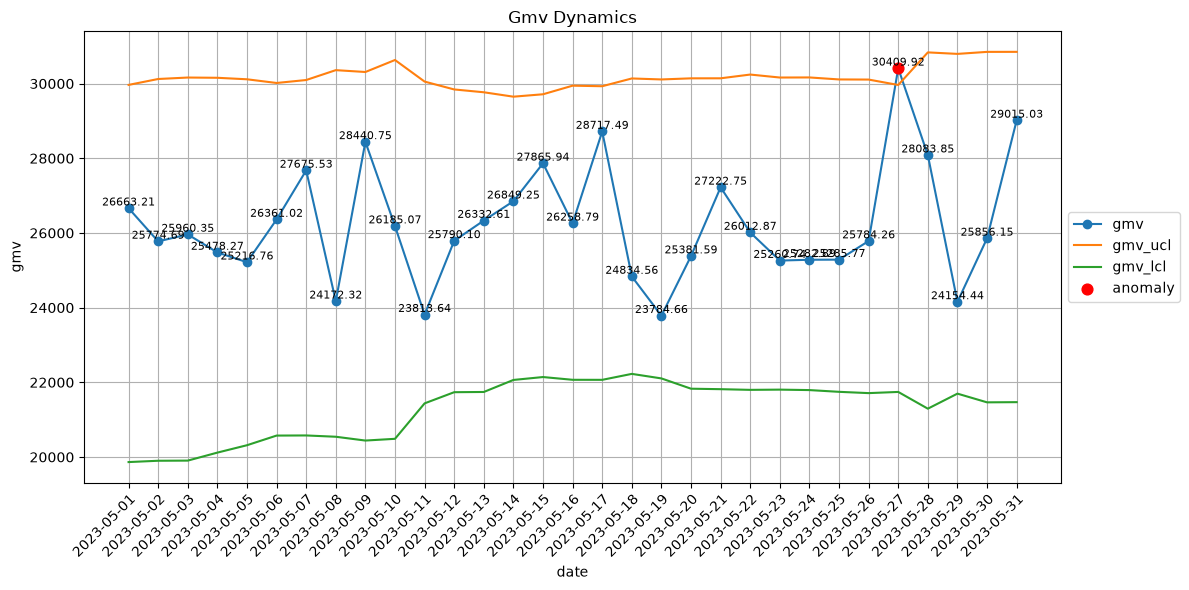

In [158]:
get_3sigma_vis(df_3sigma_may, 'date', 'gmv')

          date  items_sold       gmv  avg_item_price   gmv_mean      gmv_ssd  \
146 2023-05-27        5747  30409.92        5.291442  25853.035  1370.106836   

          gmv_ucl       gmv_lcl  is_anomaly_gmv  items_sold_mean  \
146  29963.355507  21742.714493            True           4935.0   

     items_sold_ssd  items_sold_ucl  items_sold_lcl  is_anomaly_items_sold  \
146      240.996542     5657.989626     4212.010374                   True   

     avg_item_price_mean  avg_item_price_ssd  avg_item_price_ucl  \
146             5.239688            0.144843            5.674218   

     avg_item_price_lcl  is_anomaly_avg_item_price  
146            4.805158                      False  


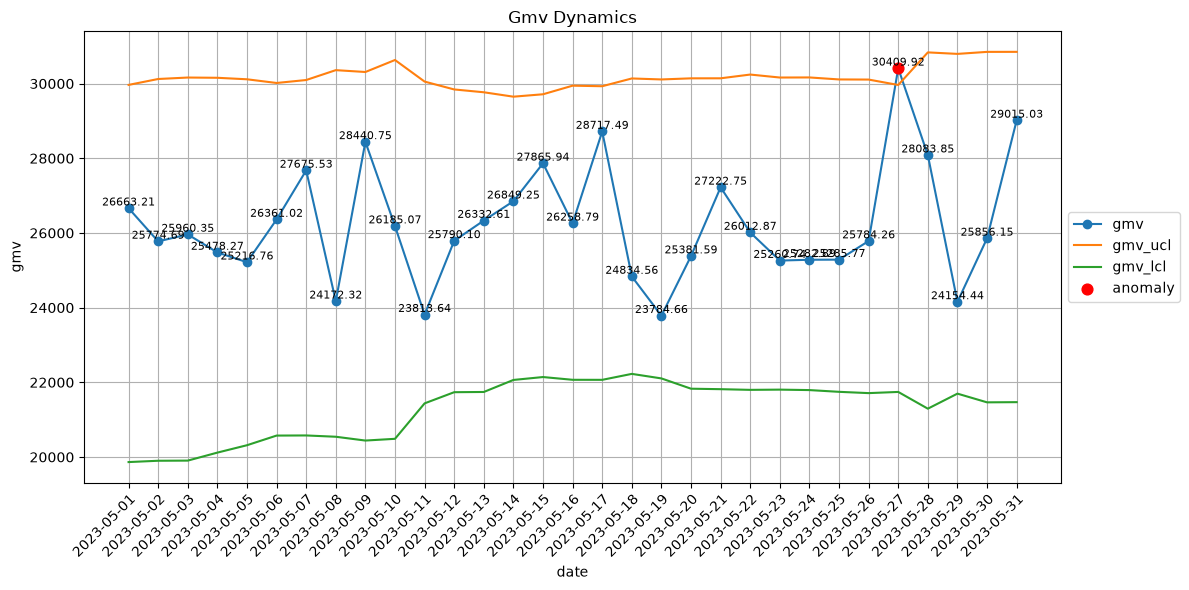

          date  items_sold       gmv  avg_item_price   gmv_mean      gmv_ssd  \
146 2023-05-27        5747  30409.92        5.291442  25853.035  1370.106836   

          gmv_ucl       gmv_lcl  is_anomaly_gmv  items_sold_mean  \
146  29963.355507  21742.714493            True           4935.0   

     items_sold_ssd  items_sold_ucl  items_sold_lcl  is_anomaly_items_sold  \
146      240.996542     5657.989626     4212.010374                   True   

     avg_item_price_mean  avg_item_price_ssd  avg_item_price_ucl  \
146             5.239688            0.144843            5.674218   

     avg_item_price_lcl  is_anomaly_avg_item_price  
146            4.805158                      False  


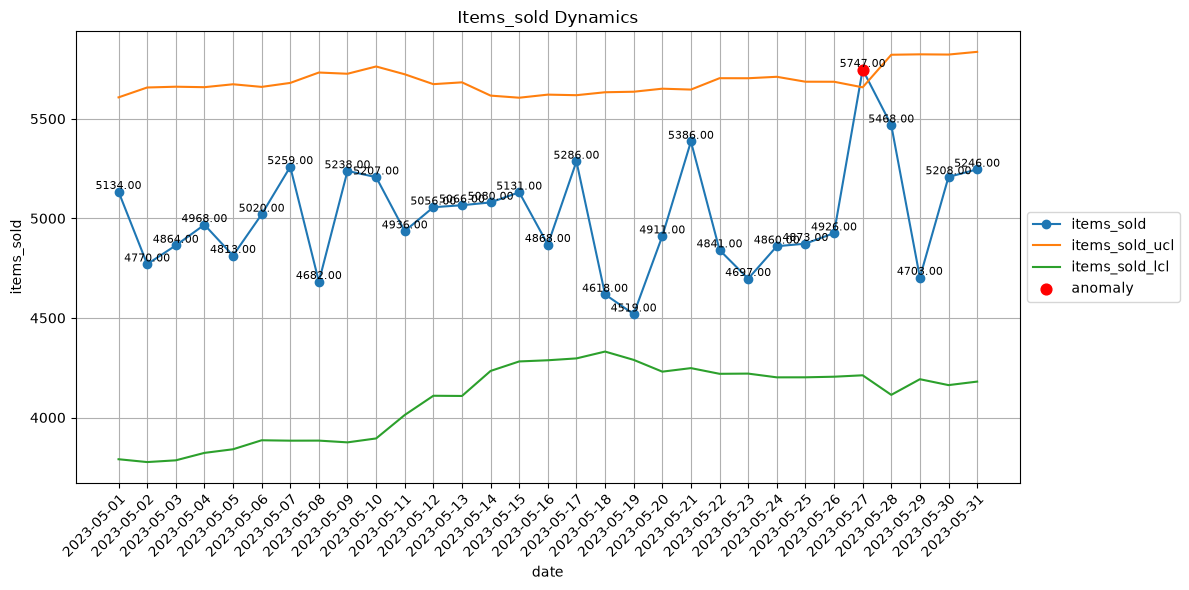

          date  items_sold       gmv  avg_item_price      gmv_mean  \
130 2023-05-11        4936  23813.64        4.824481  25745.258214   

         gmv_ssd       gmv_ucl       gmv_lcl  is_anomaly_gmv  items_sold_mean  \
130  1436.206679  30053.878251  21436.638178           False      4868.071429   

     items_sold_ssd  items_sold_ucl  items_sold_lcl  is_anomaly_items_sold  \
130      285.119849     5723.430974     4012.711883                  False   

     avg_item_price_mean  avg_item_price_ssd  avg_item_price_ucl  \
130             5.291344            0.143864            5.722935   

     avg_item_price_lcl  is_anomaly_avg_item_price  
130            4.859753                       True  


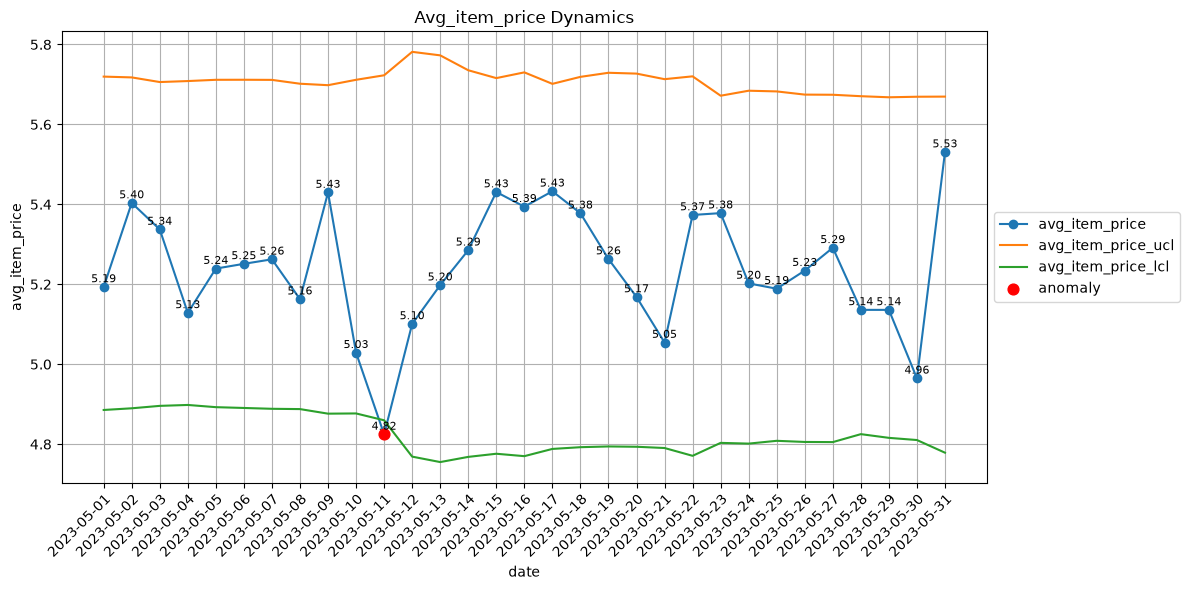

In [160]:
metrics = ['gmv', 'items_sold', 'avg_item_price']
for metric in metrics:
    df_3sigma = get_3_sigma_cl(df, metric, window=28, sigma=3)
    df_3sigma_may = df_3sigma[(df_3sigma['date'] >= pd.Timestamp(2023, 5, 1)) & (df_3sigma['date'] < pd.Timestamp(2023, 6, 1))]
    print(df_3sigma_may[df_3sigma_may[f'is_anomaly_{metric}'] == True]) 
    get_3sigma_vis(df_3sigma_may, 'date', metric)

### Крайне заметной является аномалия 27 мая в gmv, которая напрямую связана с аномалией в эту же дату количества проданных товаров - сонаправленные метрики, при этом средняя цена не менялась в эту дату
### Наблюдается резкое и значимое падение 10 мая на среднюю цену товаров, при этом значимо пострадал gmv при стабильном количестве проданных товаров

#### 3. Дельта-ряды — 2 балла

1) Рассчитайте дельты значений текущего дня с предыдущим для каждой метрики, затем примените к полученным дельтам правило 3σ:
- gmv;
- items_sold;
- avg_item_price.

Расчет производите на всем датасете. В этом пункте вы имитируете онлайн-мониторинг, поэтому проверка проводится для каждой даты, а границы контроля рассчитываются за последние 28 дней до самой даты. 

2) Постройте графики: дельты метрики + границы контроля + выделенные аномалии.

In [165]:
delta_series = df.diff().dropna()
delta_series

,date,items_sold,gmv,avg_item_price,gmv_mean,gmv_ssd,gmv_ucl,gmv_lcl,is_anomaly_gmv,items_sold_mean,items_sold_ssd,items_sold_ucl,items_sold_lcl,is_anomaly_items_sold,avg_item_price_mean,avg_item_price_ssd,avg_item_price_ucl,avg_item_price_lcl,is_anomaly_avg_item_price
29,1 days,-25.0,-1403.44,-0.396531,100.779286,3.554083,111.441535,90.117037,False,11.035714,-5.094410,-4.247517,26.318946,False,0.013696,0.007653,0.036655,-0.009263,False
30,1 days,29.0,904.34,0.234669,10.630714,-1.607753,5.807455,15.453973,False,5.750000,-0.996402,2.760795,8.739205,False,-0.006222,0.000226,-0.005543,-0.006902,False
31,1 days,205.0,923.88,-0.051219,3.458214,2.740393,11.679393,-4.762965,False,5.357143,0.211411,5.991376,4.722910,False,-0.008231,-0.010667,-0.040232,0.023770,False
32,1 days,313.0,600.14,-0.284184,136.565000,-22.382471,69.417588,203.712412,False,25.607143,-17.834006,-27.894876,79.109162,True,0.000207,0.000102,0.000511,-0.000098,False
33,1 days,59.0,778.38,0.126885,66.879286,80.934545,309.682921,-175.924349,False,20.035714,40.529862,141.625300,-101.553872,False,-0.010652,0.001602,-0.005847,-0.015457,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
360,1 days,106.0,341.38,-0.056219,46.561429,-8.737752,20.348173,72.774684,False,6.357143,-0.772036,4.041036,8.673250,False,0.003487,-0.000543,0.001858,0.005116,False
361,1 days,-570.0,-3527.36,-0.156946,51.864643,0.511049,53.397789,50.331497,False,4.892857,2.438219,12.207514,-2.421800,False,0.006858,-0.005931,-0.010936,0.024653,False
362,1 days,632.0,3138.96,-0.021211,-131.495357,104.019399,180.562841,-443.553555,False,-20.035714,11.525966,14.542183,-54.613611,False,-0.007435,0.004352,0.005620,-0.020490,False
363,1 days,-214.0,171.01,0.331440,-23.770000,-15.922725,-71.538174,23.998174,False,0.178571,0.208841,0.805093,-0.447950,False,-0.006162,0.004767,0.008140,-0.020463,False


In [173]:
df

,date,items_sold,gmv,avg_item_price,gmv_mean,gmv_ssd,gmv_ucl,gmv_lcl,is_anomaly_gmv,items_sold_mean,items_sold_ssd,items_sold_ucl,items_sold_lcl,is_anomaly_items_sold,avg_item_price_mean,avg_item_price_ssd,avg_item_price_ucl,avg_item_price_lcl,is_anomaly_avg_item_price
0,2023-01-01,2907,14944.41,5.140836,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False
1,2023-01-02,3030,16065.13,5.302023,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False
2,2023-01-03,3070,17170.30,5.592932,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False
3,2023-01-04,2708,14367.19,5.305462,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False
4,2023-01-05,3177,16918.53,5.325316,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
360,2023-12-27,3948,20759.52,5.258237,19996.648214,1140.022950,23416.717065,16576.579363,False,3779.785714,201.200905,4383.388430,3176.182999,False,5.291825,0.162483,5.779274,4.804376,False
361,2023-12-28,3378,17232.16,5.101291,20048.512857,1140.533999,23470.114854,16626.910860,False,3784.678571,203.639124,4395.595944,3173.761199,False,5.298683,0.156552,5.768338,4.829028,False
362,2023-12-29,4010,20371.12,5.080080,19917.017500,1244.553398,23650.677695,16183.357305,False,3764.642857,215.165090,4410.138127,3119.147588,False,5.291248,0.160903,5.773958,4.808538,False
363,2023-12-30,3796,20542.13,5.411520,19893.247500,1228.630673,23579.139520,16207.355480,False,3764.821429,215.373930,4410.943220,3118.699637,False,5.285086,0.165671,5.782098,4.788074,False


Empty DataFrame
Columns: [date, items_sold, gmv, avg_item_price, gmv_mean, gmv_ssd, gmv_ucl, gmv_lcl, is_anomaly_gmv, items_sold_mean, items_sold_ssd, items_sold_ucl, items_sold_lcl, is_anomaly_items_sold, avg_item_price_mean, avg_item_price_ssd, avg_item_price_ucl, avg_item_price_lcl, is_anomaly_avg_item_price]
Index: []


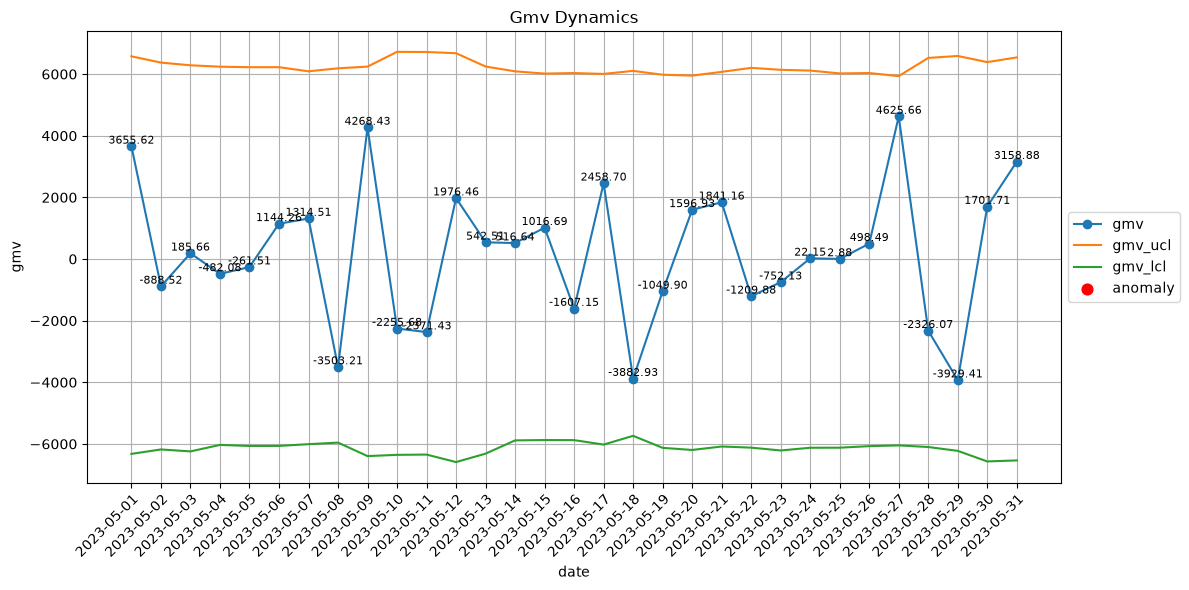

Empty DataFrame
Columns: [date, items_sold, gmv, avg_item_price, gmv_mean, gmv_ssd, gmv_ucl, gmv_lcl, is_anomaly_gmv, items_sold_mean, items_sold_ssd, items_sold_ucl, items_sold_lcl, is_anomaly_items_sold, avg_item_price_mean, avg_item_price_ssd, avg_item_price_ucl, avg_item_price_lcl, is_anomaly_avg_item_price]
Index: []


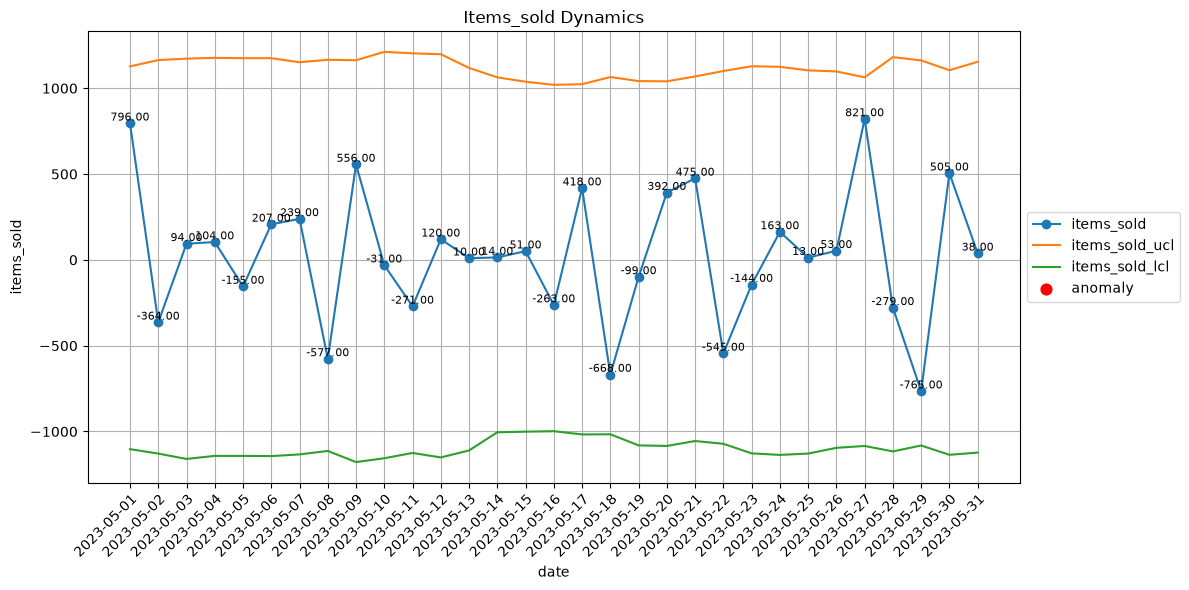

          date  items_sold       gmv  avg_item_price      gmv_mean  \
150 2023-05-31        5246  29015.03        0.566188  26159.726429   

         gmv_ssd       gmv_ucl       gmv_lcl  is_anomaly_gmv  items_sold_mean  \
150  1563.588174  30850.490951  21468.961906           False          5008.25   

     items_sold_ssd  items_sold_ucl  items_sold_lcl  is_anomaly_items_sold  \
150      275.953113     5836.109338     4180.390662                  False   

     avg_item_price_mean  avg_item_price_ssd  avg_item_price_ucl  \
150            -0.015671            0.159238            0.462041   

     avg_item_price_lcl  is_anomaly_avg_item_price  
150           -0.493384                       True  


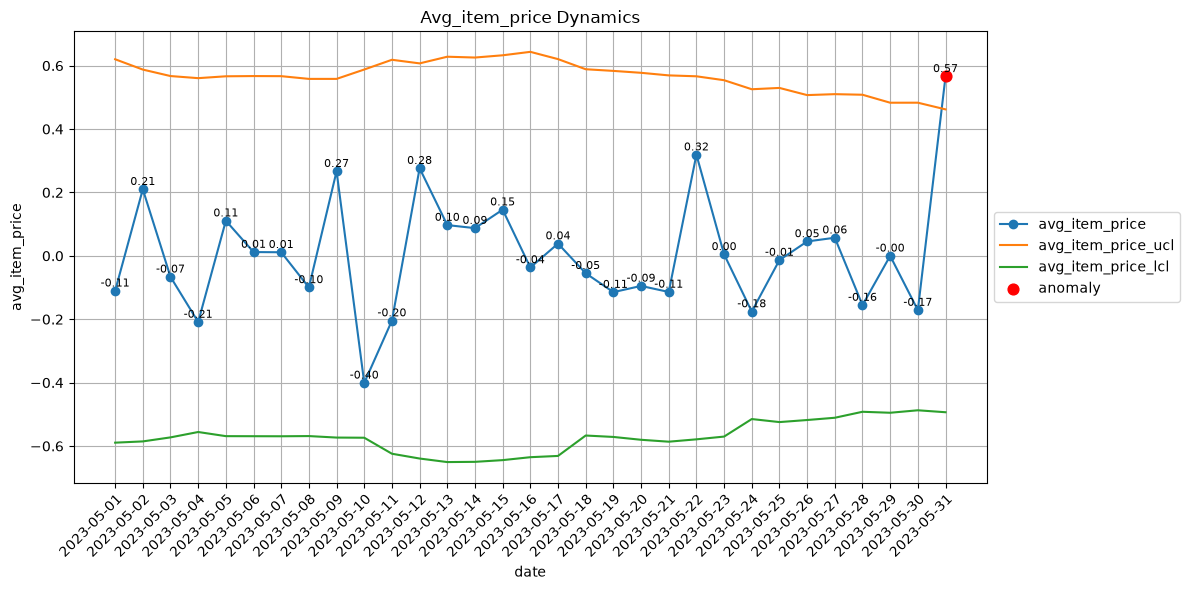

In [185]:
for metric in metrics:
    delta_series = df.copy()
    delta_series[metric] = df[metric].diff().dropna()
    df_3sigma = get_3_sigma_cl(delta_series, metric, window=28, sigma=3)
    df_3sigma_may = df_3sigma[(df_3sigma['date'] >= pd.Timestamp(2023, 5, 1)) & (df_3sigma['date'] < pd.Timestamp(2023, 6, 1))]
    print(df_3sigma_may[df_3sigma_may[f'is_anomaly_{metric}'] == True]) 
    get_3sigma_vis(df_3sigma_may, 'date', metric)

### По относительным значениям только средняя цена товара в последний день мая показывает аномально большое значение при окне в 28 дней, из-за небольшого количества доп проданных товаров в этот день gmv прирос не значимо

#### 4. Generalized ESD — 2 балла

1) Реализуйте Generalized ESD. Обратите внимание, с какими данными работает метод — онлайн или батч? Учтите это в реализации.
2) Найдите аномалии для дельт каждой метрики ЗА МАЙ (используйте данные, полученные на прошлом шаге):
- gmv;
- items_sold;
- avg_item_price.
3) Сравните результаты с правилом 3σ на дельтах: разошлись ли методы?

*Советую обернуть Generalized ESD в функцию, она пригодится на следующем шаге.*

In [263]:
def generalized_ESD(df, metric, alpha=0.05, max_anomaly = 5):
    x = df[metric].dropna().astype(float)
    N = x.size
    removed = []
    anomalies = 0
    for i in range(1, max_anomaly+1):

        mean = x.mean()
        s = x.std(ddof=1)
        diff = (x - mean).abs()
        idx = diff.idxmax()
        G = diff.loc[idx] / s
        p =1 - alpha/(2*(N - i + 1))
    
        tcrit = t.ppf(p, df=N-i-1)
        lamba = (N-i)* tcrit / np.sqrt((N - i - 1 + (tcrit**2)) * (N - i + 1))
    
        if (G > lamba):
             anomalies = i

        removed.append(idx)
        x = x.drop(idx)

    return removed[:anomalies]

In [277]:
may = delta_series[(delta_series['date'] >= pd.Timestamp(2023, 5, 1)) & (delta_series['date'] < pd.Timestamp(2023, 6, 1))]

for metric in metrics:
    idx = generalized_ESD(may, metric)
    print(metric, may.loc[idx, 'date'])

gmv Series([], Name: date, dtype: datetime64[ns])
items_sold Series([], Name: date, dtype: datetime64[ns])
avg_item_price 150   2023-05-31
Name: date, dtype: datetime64[ns]


### Generalized ESD работает с батчем данных - ретроспективный анализ: он смотрит сразу на весь ряд и по очереди проверяет самые сильные отклонения. Ищет до k выбросов, на каждом шаге удаляя самые экстремальные точки

### Правило 3σ и Generalized ESD на дельтах нашли в мае только скачок средней цены товара 31.05, а по GMV и items_sold аномалий не выявлено 

#### 5. STL-разложение — 2 балла

1) Для каждой метрики выполните STL-разложение с недельной сезонностью (7 дней) на данных всего датасета:
- gmv;
- items_sold;
- avg_item_price.

Используйте STL из библиотеки statsmodels (уже есть в импортах).
  
2) Для каждой метрики визуализируйте компоненты: тренд, сезонность, остатки (на всем датасете).

4) На остатках примените Generalized ESD, можете использовать функцию из прошлого шага. Это упражнение проделываем только на данных ЗА МАЙ.

5) Подумайте, для каждой ли метрики имеет смысл использовать STL, везде ли визуально присутствуют тренд и недельная сезонность?

In [191]:
def get_stl_results(df, x, metric, period=7):
    ts = df.set_index(x)[metric]
    stl = STL(ts, period=period, robust=True)
    stl_result = stl.fit()

    return stl_result

In [193]:
def get_stl_viz(stl_result, metric):
    trend = stl_result.trend
    seasonal = stl_result.seasonal
    resid = stl_result.resid
    observed = stl_result.observed

    fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
    
    axes[0].plot(observed, label='Observed')
    axes[0].legend(loc='upper left')
    
    axes[1].plot(trend, color='orange', label='Trend')
    axes[1].legend(loc='upper left')
    
    axes[2].plot(seasonal, color='green', label='Seasonal')
    axes[2].legend(loc='upper left')
    
    axes[3].plot(resid, color='red', label='Residuals')
    axes[3].legend(loc='upper left')

    fig.suptitle(f'{metric} STL', fontsize=14)
    plt.tight_layout()
    plt.show()

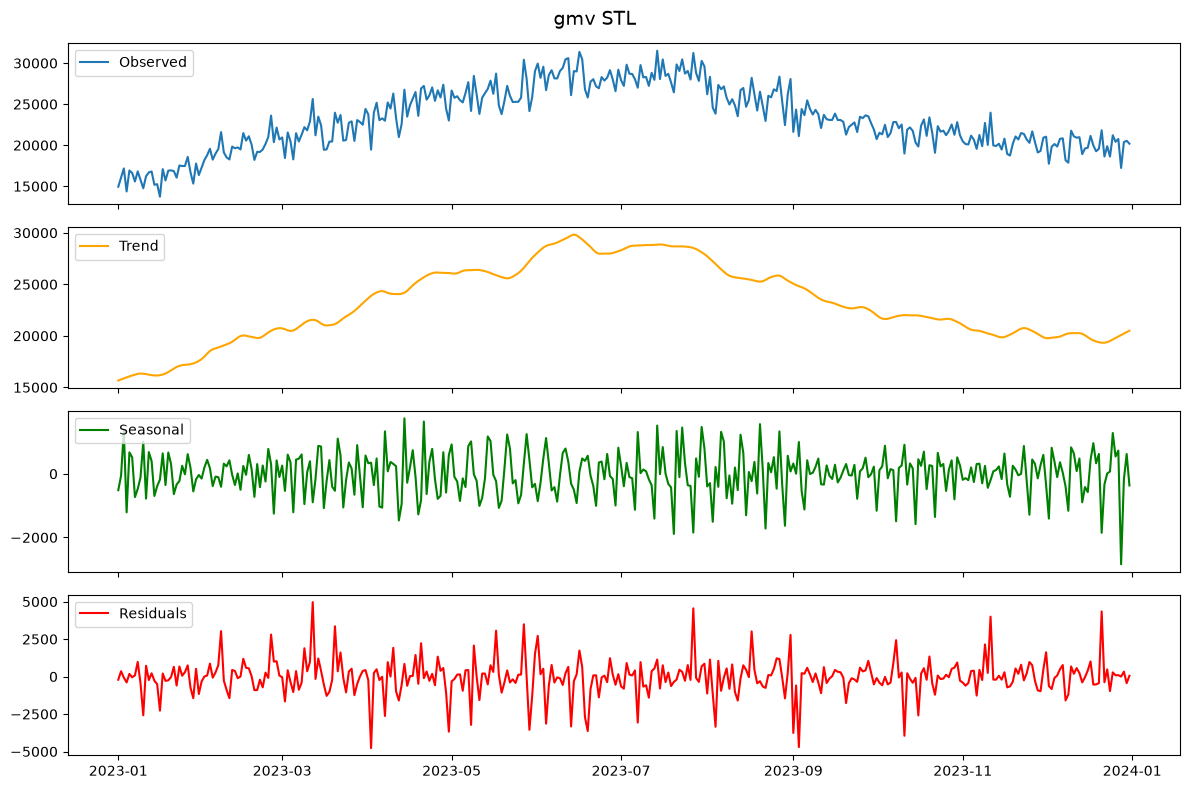

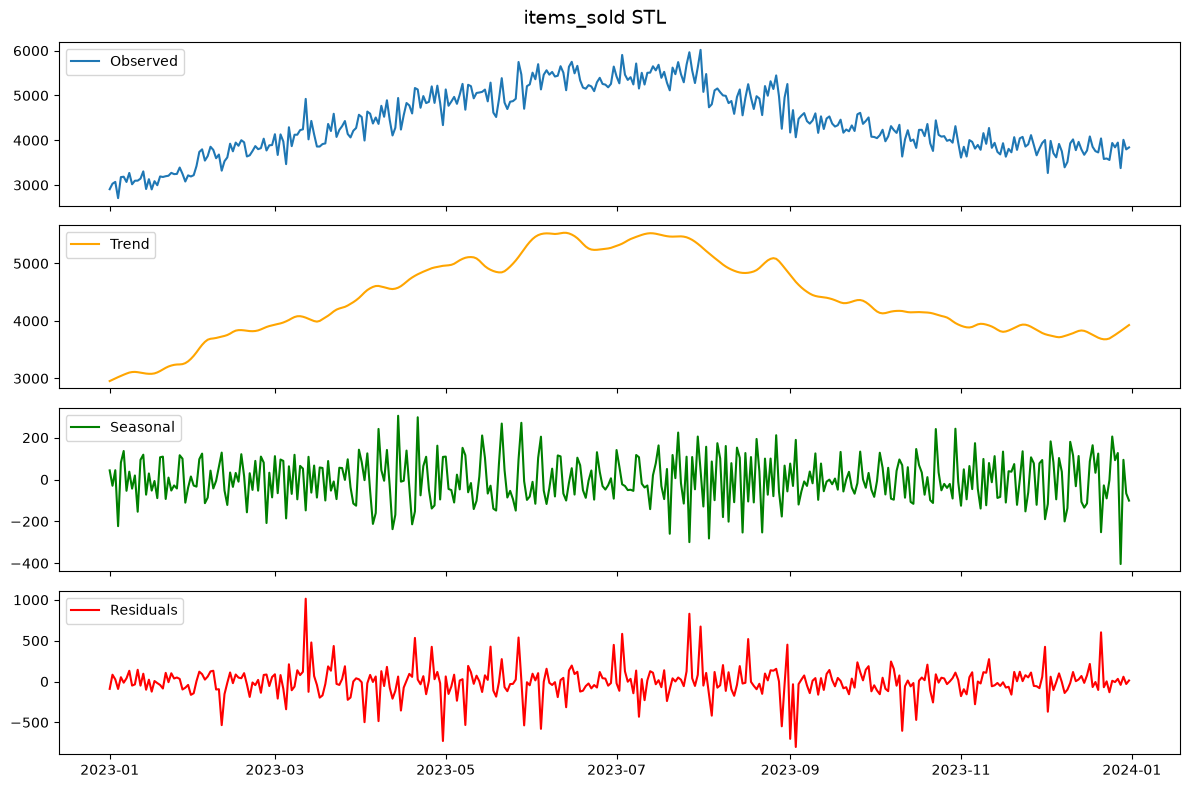

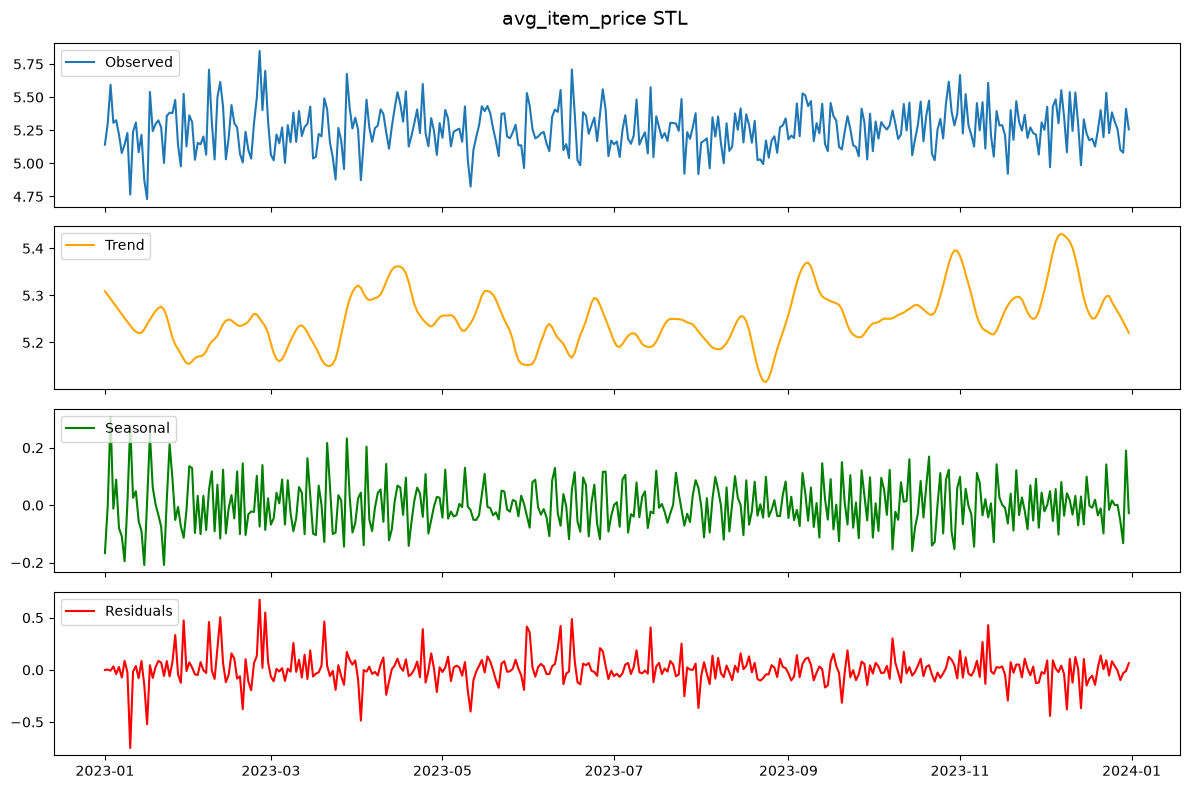

In [311]:
for metric in metrics:
    df_stl = get_stl_results(df, 'date', metric)
    get_stl_viz(df_stl, metric)
    

In [328]:
for metric in metrics:
    resid = get_stl_results(df, 'date', metric).resid
    resid_may = resid[resid.index.month == 5]
    print(metric, generalized_ESD(resid_may.to_frame(metric), metric))

gmv [Timestamp('2023-05-29 00:00:00'), Timestamp('2023-05-27 00:00:00'), Timestamp('2023-05-08 00:00:00'), Timestamp('2023-05-17 00:00:00')]
items_sold [Timestamp('2023-05-27 00:00:00'), Timestamp('2023-05-29 00:00:00'), Timestamp('2023-05-08 00:00:00'), Timestamp('2023-05-17 00:00:00')]
avg_item_price [Timestamp('2023-05-31 00:00:00'), Timestamp('2023-05-11 00:00:00')]


### на остатках STL за май Generalized ESD нашёл большое количество аномалий по каждой метрике. После удаления тренда и сезонности оставшиеся колебания в мае показывают большие отклонения в residuals, появились дополнительные точки 29.05, 08.05, 17.05 в gmv и items_sold, а средняя цена товара обозначила до этого выявленные обе аномалии 11.05 и 31.05


#### 6. EWMA — 2 балла

1) Реализуйте метод EWMA для каждой метрики:
- gmv;
- items_sold;
- avg_item_price.

Сглаженная статистика считается рекуррентно с параметром $\lambda = 0.2$:

$$
z_t = \lambda x_t + (1-\lambda)\, z_{t-1}, \qquad z_0 = x_0,
$$

где $x_t$ — исходное дневное значение метрики. В pandas это делает [встроенная функция экспоненциального сглаживания](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.ewm.html) — обратите внимание на параметр `adjust=False`, именно он дает рекуррентную форму выше.

Контрольные границы задаются как

$$
\mu_t \pm L\,\sigma_t \sqrt{\frac{\lambda}{2-\lambda}}, \qquad L = 3.
$$

Здесь $\mu_t$ и $\sigma_t$ — среднее и стандартное отклонение **исходного ряда $x_t$**, а не сглаженного $z_t$, посчитанные на скользящем окне 28 дней. Множитель $\sqrt{\lambda/(2-\lambda)}$ — асимптотическое приближение отношения дисперсии сглаженной статистики к дисперсии сырых наблюдений: он уже учитывает, что $z_t$ колеблется меньше, чем $x_t$, поэтому подставлять в формулу разброс самого $z_t$ нельзя — сжатие применится дважды, и коридор получится слишком узким.

Окно для $\mu_t$ и $\sigma_t$ должно заканчиваться на предыдущем дне (`.rolling(28).mean().shift(1)`), иначе текущее наблюдение попадёт в собственную оценку разброса и аномалия спрячет сама себя.

2) Постройте графики: сглаженная метрика + границы контроля + выделенные аномалии.
3) Напишите, какой из подходов вам больше всего понравился для онлайн-мониторинга, а какой — для ретроспективного анализа, и почему. Тут нет правильного ответа :)

In [300]:
def ewma(df, metric, lamda=0.2, L=3, window=28):
    df = df.copy()
    df[f'{metric}_z'] = df[metric].ewm(alpha = lamda, adjust=False).mean()
    mean = df[metric].shift(1).rolling(window=window, min_periods=window).mean()
    sigma = df[metric].shift(1).rolling(window=window, min_periods=window).std(ddof=1)
    df[f'upper_{metric}'] = mean + L*sigma* np.sqrt(lamda / (2 - lamda))
    df[f'lower_{metric}'] = mean - L*sigma* np.sqrt(lamda / (2 - lamda))
    df[f'anomaly_ewma_{metric}'] = (df[f'{metric}_z'] < df[f'lower_{metric}']) | (df[f'{metric}_z'] > df[f'upper_{metric}'])
    return df

gmv
Empty DataFrame
Columns: [date, gmv, gmv_z, lower_gmv, upper_gmv]
Index: []


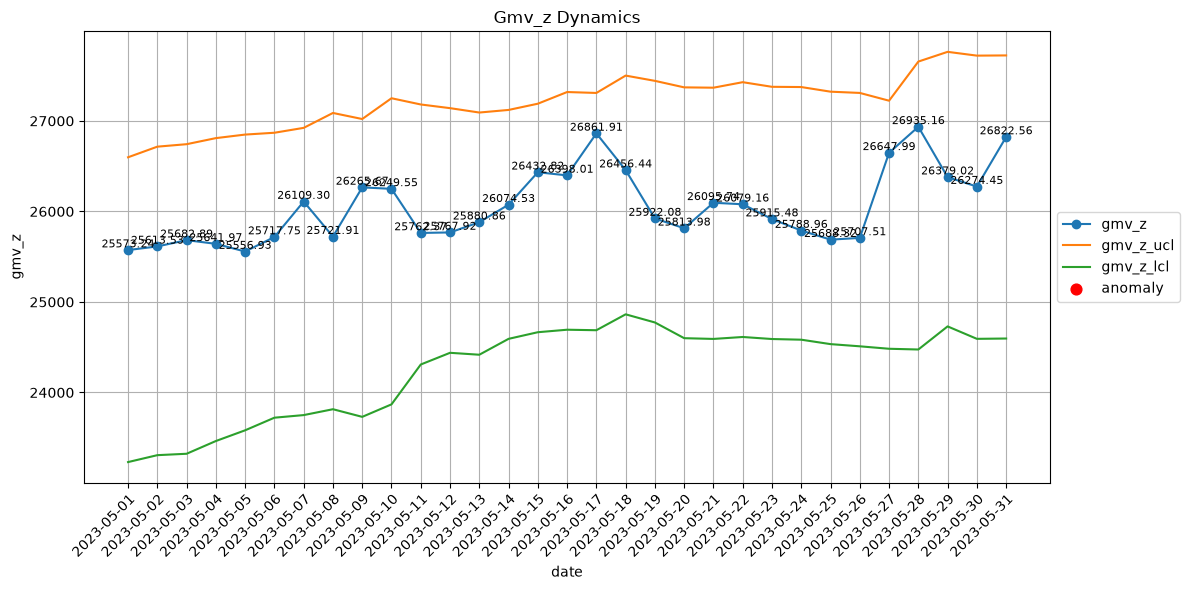

items_sold
Empty DataFrame
Columns: [date, items_sold, items_sold_z, lower_items_sold, upper_items_sold]
Index: []


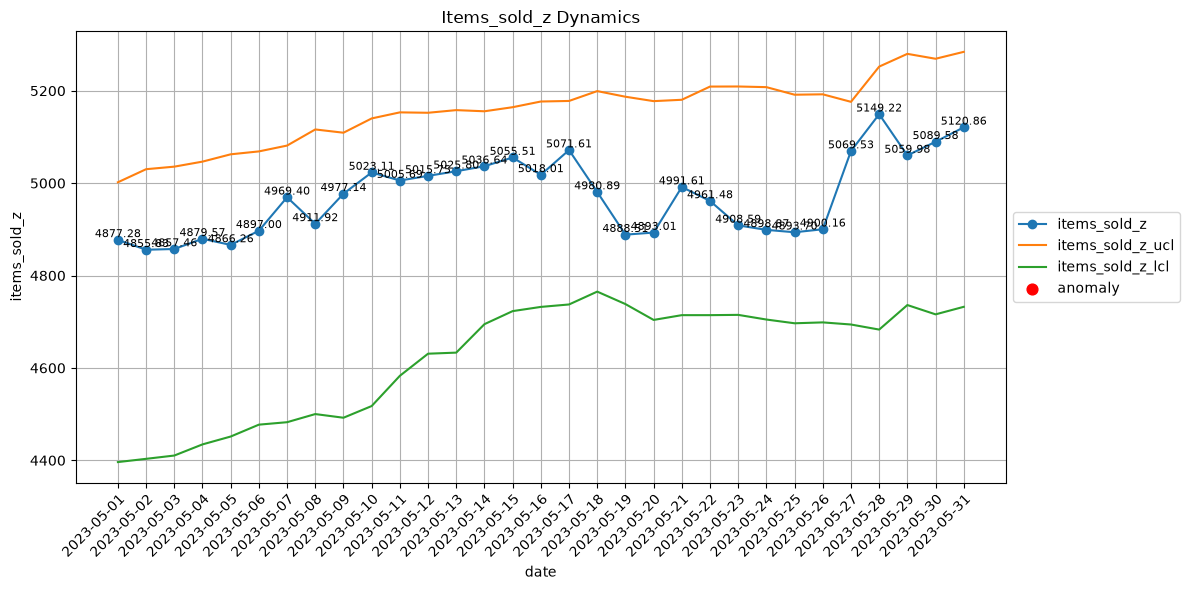

avg_item_price
          date  avg_item_price  avg_item_price_z  lower_avg_item_price  \
130 2023-05-11        4.824481          5.145622               5.14748   

     upper_avg_item_price  
130              5.435207  


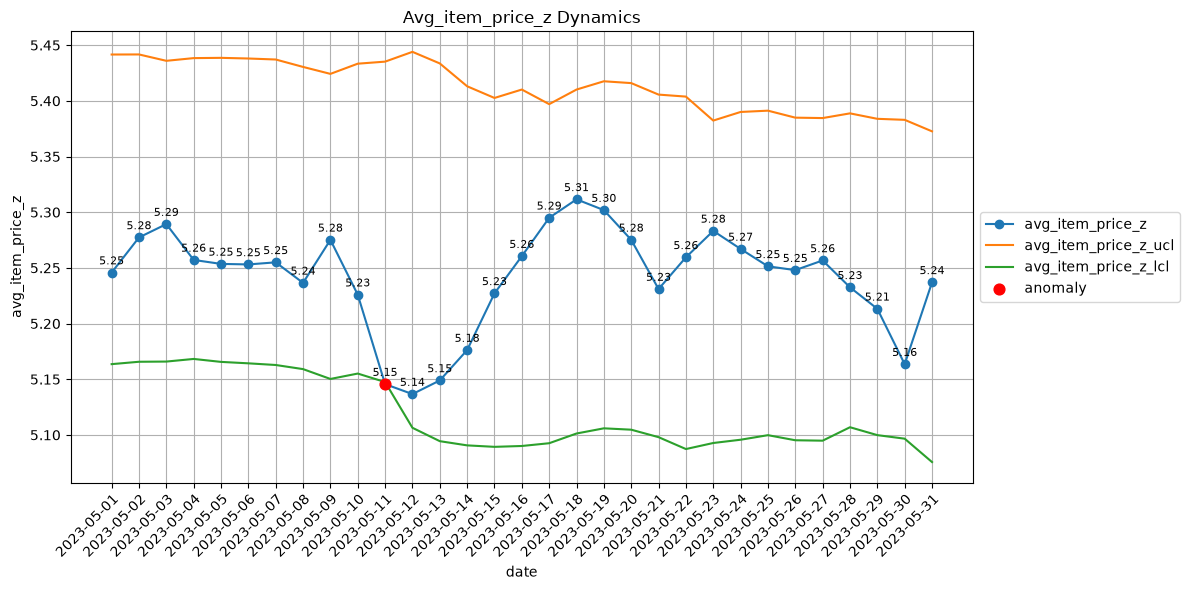

In [306]:
for metric in metrics:
    df_ewma = ewma(df[['date', metric]], metric)
    df_ewma_may = df_ewma[(df_ewma['date'] >= pd.Timestamp(2023, 5, 1)) & (df_ewma['date'] < pd.Timestamp(2023, 6, 1))].copy()

    print(metric)
    print(df_ewma_may.loc[df_ewma_may[f'anomaly_ewma_{metric}'], ['date', metric, f'{metric}_z', f'lower_{metric}', f'upper_{metric}']])

    df_ewma_may[f'{metric}_z_ucl'] = df_ewma_may[f'upper_{metric}']
    df_ewma_may[f'{metric}_z_lcl'] = df_ewma_may[f'lower_{metric}']
    df_ewma_may[f'is_anomaly_{metric}_z'] = df_ewma_may[f'anomaly_ewma_{metric}']

    get_3sigma_vis(df_ewma_may, 'date', f'{metric}_z')

### EWMA в мае нашёл только падение средней цены товара 11.05, то же, что и обычное правило 3σ. Всплеск GMV и числа товаров 27.05 EWMA не поймал: это был одиночный скачок, а сглаженная статистика реагирует на него слабо. Зато EWMA лучше подходит для ловли небольших, но устойчивых сдвигов, которые длятся несколько дней.

### Вывод: Для онлайн-мониторинга мне больше понравился EWMA. Он считается просто и быстро и меньше дёргается из-за единичного шума, поэтому будет меньше ложных алертов. При этом он хорошо замечает, когда метрика постепенно уезжает. Для резких одиночных падений его можно дополнить обычным правилом 3σ.

### Для ретроспективного анализа мне больше понравилась метод STL + Generalized ESD. В ходе анализа именно он на оффлайн сегменте выделил наибольшее количество аномалий обобщив выводы всех предыдущих методов, за такую комплексноть однозначно лайк